# UHSLC seasonal SLA forecast — Quinta Playa

Reads the UHSLC multi-model ensemble (top-5 by ACC, incl. damped persistence) gridded forecast
and extracts the monthly SLA forecast at Quinta Playa.

**What the forecast variable is** (UHSLC forecast page):
- `SSHa` = monthly sea surface height anomaly, **seasonal cycle removed** (fixed 1993–2016 monthly climatology)
  and **linearly detrended** (trend fitted over 1993–2025, evaluated and removed for every month incl. forecast months).
- Units are not stated in the file; values (±0.7 m max globally) and the page's RMSE in metres indicate **metres**.
- 1° grid, 6 leads. Lead 1 = the initialisation month itself.

So this is **not** directly the same quantity as the DUACS SLA in the water-level series (1993–2012 reference,
seasonal cycle and trend included). Section 4 puts it back onto that basis.

In [11]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import os

OUTDIR = os.path.join('..', 'data', 'sla')

FC_FILE = os.path.join(OUTDIR, 'ensemble_top5_ACC_withDP_altimetry_realtime_SSHa_linearly_detrended_init_2026-09.nc')

DUACS_FILE = os.path.join(OUTDIR, 'sla_quinta_daily.csv')

# Quinta Playa Coordinates
QP_LAT, QP_LON = -1.006, -91.08

COLS = ["#0a91a1", "#74c9b9", "#f47c53", "#f8a953"]

## 1. Open the forecast

In [2]:
ds = xr.open_dataset(FC_FILE).isel(init=0)   # single initialisation
print('init:', pd.to_datetime(ds.init.values).strftime('%Y-%m'))
print('valid months:', list(pd.to_datetime(ds.valid_time.values).strftime('%Y-%m')))
ds

init: 2026-09
valid months: ['2026-09', '2026-10', '2026-11', '2026-12', '2027-01', '2027-02']


<xarray.Dataset> Size: 119MB
Dimensions:               (leadtime: 6, lat: 132, lon: 360, rank: 5, model: 11)
Coordinates:
  * leadtime              (leadtime) int32 24B 1 2 3 4 5 6
  * lat                   (lat) float32 528B -65.5 -64.5 -63.5 ... 64.5 65.5
  * lon                   (lon) float32 1kB 0.5 1.5 2.5 ... 357.5 358.5 359.5
  * rank                  (rank) int16 10B 1 2 3 4 5
  * model                 (model) <U18 792B 'ecmwf_seas5' ... 'damped_persist...
    init                  datetime64[ns] 8B 2026-09-15
Data variables:
    SSHa_mean             (leadtime, lat, lon) float32 1MB ...
    SSHa_spread           (leadtime, lat, lon) float32 1MB ...
    model_count           (leadtime, lat, lon) int16 570kB ...
    selected_model_index  (rank, leadtime, lat, lon) int16 3MB ...
    selected_model_name   (rank, leadtime, lat, lon) <U18 103MB ...
    selected_model_acc    (rank, leadtime, lat, lon) float32 6MB ...
    valid_time            (leadtime) datetime64[ns] 48B 2026-09-15 ... 2027-0...
    SSHa_p025             (leadtime, lat, lon) float32 1MB ...
    SSHa_p16              (leadtime, lat, lon) float32 1MB ...
    SSHa_p84              (leadtime, lat, lon) float32 1MB ...
    SSHa_p975             (leadtime, lat, lon) float32 1MB ...
Attributes:
    ensemble_name:             ensemble_top5_ACC_location_lead_withDP
    target:                    altimetry
    models_ranked:             ecmwf_seas5, meteo_france, dwd, cmcc, uk_metof...
    rank_metric:               ACC
    spread_definition:         equal-weight Gaussian-mixture standard deviati...
    quantile_definition:       exact equal-weight Gaussian-mixture CDF quanti...
    selection_rule:            top k models are selected independently at eac...
    lead_alignment_rule:       dynamical source leads 0..5 and statistical le...
    damped_persistence:        included as a candidate model for ranking and ...
    disabled_realtime_models:  access_s2_ecmwf
    bad_value_mask:            source SSHa_mean with abs(value) > 10 m is ign...

## 2. Nearest ocean grid cell

Isabela itself masks the cells at (-0.5°, 268.5°E) and (-0.5°, 269.5°E), so pick the nearest cell
that has data. Neighbouring ocean cells differ by < 2 cm, so the choice is not sensitive.

In [12]:
lon360 = QP_LON % 360
valid = ds.model_count.isel(leadtime=0) > 0

lat2d, lon2d = xr.broadcast(ds.lat, ds.lon)
dist = np.hypot(lat2d - QP_LAT, (lon2d - lon360) * np.cos(np.deg2rad(QP_LAT)))
dist = dist.where(valid)
iy, ix = np.unravel_index(np.nanargmin(dist.values), dist.shape)
cell = ds.isel(lat=iy, lon=ix)
print(f'Using cell {float(cell.lat):.1f}N, {float(cell.lon)-360:.1f}E  '
      f'({float(dist[iy, ix])*111:.0f} km from site)')

# sensitivity: the surrounding ocean cells
box = ds.SSHa_mean.sel(lat=slice(QP_LAT-1.2, QP_LAT+1.2), lon=slice(lon360-1.2, lon360+1.2))
box.to_dataframe().SSHa_mean.unstack(['lat', 'lon']).set_index(
    pd.to_datetime(ds.valid_time.values).strftime('%Y-%m')).round(3)

Using cell -1.5N, -91.5E  (72 km from site)


lat       -1.5         -0.5      
lon      268.5  269.5 268.5 269.5
2026-09  0.303  0.285   NaN   NaN
2026-10  0.297  0.277   NaN   NaN
2026-11  0.289  0.280   NaN   NaN
2026-12  0.272  0.261   NaN   NaN
2027-01  0.217  0.214   NaN   NaN
2027-02  0.141  0.146   NaN   NaN

## 3. Forecast table at Quinta Playa (detrended, deseasonalised anomaly, m)

In [13]:
fc = pd.DataFrame({
    'sla_fc_mean':  cell.SSHa_mean.values,
    'sla_fc_sd':    cell.SSHa_spread.values,
    'sla_fc_p025':  cell.SSHa_p025.values,
    'sla_fc_p16':   cell.SSHa_p16.values,
    'sla_fc_p84':   cell.SSHa_p84.values,
    'sla_fc_p975':  cell.SSHa_p975.values,
    'n_models':     cell.model_count.values,
}, index=pd.to_datetime(cell.valid_time.values).to_period('M'))
fc.index.name = 'month'

# which models were selected, with their anomaly correlation skill, per lead
models = pd.DataFrame(cell.selected_model_name.values.T, index=fc.index,
                      columns=[f'rank{r}' for r in cell['rank'].values])
acc = pd.DataFrame(cell.selected_model_acc.values.T, index=fc.index,
                   columns=[f'acc{r}' for r in cell['rank'].values]).round(2)
display(fc.round(3))
display(models.join(acc))

,sla_fc_mean,sla_fc_sd,sla_fc_p025,sla_fc_p16,sla_fc_p84,sla_fc_p975,n_models
month,,,,,,,
2026-09,0.303,0.031,0.259,0.272,0.346,0.365,5
2026-10,0.297,0.039,0.227,0.252,0.339,0.366,5
2026-11,0.289,0.043,0.207,0.241,0.333,0.369,5
2026-12,0.272,0.039,0.192,0.235,0.309,0.350,5
2027-01,0.217,0.048,0.118,0.169,0.264,0.308,5
2027-02,0.141,0.048,0.046,0.089,0.189,0.229,5


,rank1,rank2,rank3,rank4,rank5,acc1,acc2,acc3,acc4,acc5
month,,,,,,,,,,
2026-09,ecmwf_seas5,uk_metoffice,cmcc,meteo_france,gem52_nemo,0.98,0.97,0.96,0.95,0.91
2026-10,ecmwf_seas5,uk_metoffice,cmcc,meteo_france,gem52_nemo,0.94,0.93,0.91,0.88,0.87
2026-11,ecmwf_seas5,uk_metoffice,cmcc,gem52_nemo,meteo_france,0.89,0.89,0.83,0.82,0.80
2026-12,ecmwf_seas5,uk_metoffice,cmcc,gem52_nemo,meteo_france,0.85,0.83,0.79,0.77,0.71
2027-01,ecmwf_seas5,uk_metoffice,cmcc,gem52_nemo,meteo_france,0.82,0.78,0.76,0.75,0.64
2027-02,ecmwf_seas5,uk_metoffice,cmcc,gem52_nemo,meteo_france,0.77,0.75,0.73,0.69,0.58


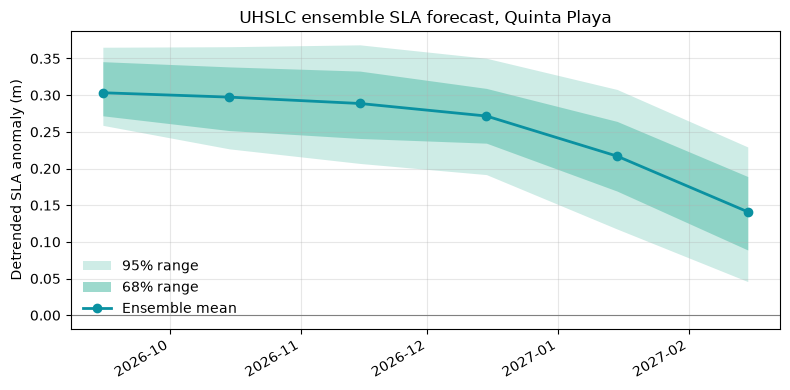

In [14]:
t = fc.index.to_timestamp() + pd.Timedelta(days=14)
fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(t, fc.sla_fc_p025, fc.sla_fc_p975, color=COLS[1], alpha=0.35, lw=0, label='95% range')
ax.fill_between(t, fc.sla_fc_p16, fc.sla_fc_p84, color=COLS[1], alpha=0.7, lw=0, label='68% range')
ax.plot(t, fc.sla_fc_mean, 'o-', color=COLS[0], lw=2, label='Ensemble mean')
ax.axhline(0, color='0.5', lw=0.8)
ax.set_ylabel('Detrended SLA anomaly (m)')
ax.set_title(f'UHSLC ensemble SLA forecast, Quinta Playa')
ax.legend(frameon=False, loc='lower left')
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
fig.savefig('uhslc_sla_forecast_quinta_playa.png', dpi=200)

## 4. Put the forecast on the DUACS SLA / MSS datum

The forecast removed two things that the observed DUACS SLA series still contains, so add them back,
both fitted **at the site from your own DUACS monthly SLA** using the same recipe UHSLC used:

    SLA_DUACS(t) ≈ clim_1993–2016[month(t)] + trend_1993–2025(t) + SSHa_fc(t)

Because the climatology and trend are computed from the DUACS series itself, the result inherits its
1993–2012 reference and MSS datum, and is continuous with the hindcast `water_level`.
Then `water_level_egm2008 = water_level + 0.276` (see `vertical-datum-convention.md`).

`sla_obs` below must be a **monthly-mean** DUACS SLA `pd.Series` (m) at the site with a monthly `PeriodIndex`,
e.g. from `marcus_sla.ipynb` via `.resample('MS').mean().to_period('M')`.

In [15]:
def forecast_to_duacs_basis(fc, sla_obs):
    """Add back the 1993–2016 monthly climatology and 1993–2025 linear trend (UHSLC recipe)."""
    obs = sla_obs.copy()
    clim = obs['1993':'2016'].groupby(obs['1993':'2016'].index.month).mean()
    anom = obs - clim.reindex(obs.index.month).values

    fit = anom['1993':'2025'].dropna()
    x = lambda idx: (idx.year + (idx.month - 0.5) / 12).values      # decimal year
    slope, intercept = np.polyfit(x(fit.index), fit.values, 1)

    add_back = clim.reindex(fc.index.month).values + intercept + slope * x(fc.index)
    out = fc.copy()
    for c in [c for c in fc.columns if c.startswith('sla_fc_') and c != 'sla_fc_sd']:
        out[c.replace('sla_fc_', 'sla_')] = fc[c] + add_back      # sd is unchanged by a shift
    out['add_back'] = add_back
    print(f'trend at site: {slope*1000:.1f} mm/yr')
    return out

sla_daily = pd.read_csv(DUACS_FILE, parse_dates=['time'], index_col='time')
sla_obs = sla_daily['sla'].resample('MS').mean().to_period('M')  # monthly DUACS SLA at Quinta Playa (MSS datum, m)
# Convert the forecast to the DUACS basis
fc_duacs = forecast_to_duacs_basis(fc, sla_obs)
#fc_duacs['sla_mean_egm2008'] = fc_duacs['sla_mean'] + 0.276   # only if SLA-only level is wanted vs DEM

trend at site: 2.4 mm/yr


## 5. Plot both historical and forecasted SLA

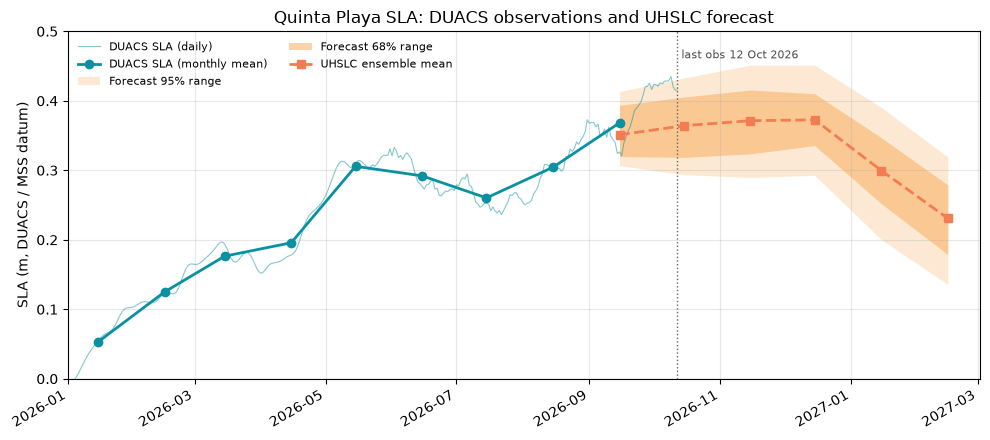

In [20]:
obs_d = sla_daily.loc['2026-01-01':, 'sla']
obs_m = sla_obs['2026-01':'2026-09']
t_obs = obs_m.index.to_timestamp() + pd.Timedelta(days=14)
t_fc  = fc_duacs.index.to_timestamp() + pd.Timedelta(days=14)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(obs_d.index, obs_d, color=COLS[0], lw=0.8, alpha=0.5, label='DUACS SLA (daily)')
ax.plot(t_obs, obs_m, 'o-', color=COLS[0], lw=2, label='DUACS SLA (monthly mean)')
ax.fill_between(t_fc, fc_duacs.sla_p025, fc_duacs.sla_p975, color=COLS[3], alpha=0.25, lw=0, label='Forecast 95% range')
ax.fill_between(t_fc, fc_duacs.sla_p16, fc_duacs.sla_p84, color=COLS[3], alpha=0.5, lw=0, label='Forecast 68% range')
ax.plot(t_fc, fc_duacs.sla_mean, 's--', color=COLS[2], lw=2, label='UHSLC ensemble mean')
ax.axvline(obs_d.index[-1], color='0.4', ls=':', lw=1)
ax.text(obs_d.index[-1], ax.get_ylim()[1], f' last obs {obs_d.index[-1]:%d %b %Y}', va='top', fontsize=8, color='0.3')
ax.axhline(0, color='0.5', lw=0.8)
ax.set_ylabel('SLA (m, DUACS / MSS datum)')
ax.set_title(f'Quinta Playa SLA: DUACS observations and UHSLC forecast')
ax.legend(frameon=False, loc='upper left', fontsize=8, ncol=2)
ax.grid(alpha=0.3)
ax.set_xlim(pd.Timestamp('2026-01-01'), t_fc[-1] + pd.Timedelta(days=15))
ax.set_ylim(0, 0.5)
fig.autofmt_xdate()
plt.tight_layout()
fig.savefig('sla_obs_vs_forecast_quinta_playa.png', dpi=200)

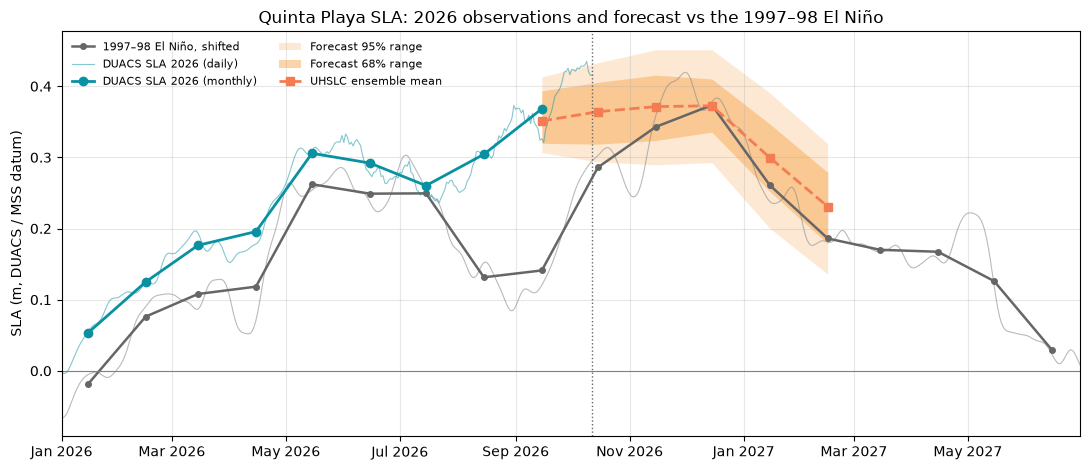

In [27]:
SHIFT_YEARS = 29                      # 1997 -> 2026
ADD_TREND = False                      # lift 1997-98 by the long-term trend so both sit on the same mean sea level

# 1997-98 El Niño, moved forward to line up by calendar month
nino = sla_daily.loc['1997-01-01':'1998-06-30', 'sla'].copy()
nino_m = sla_obs['1997-01':'1998-06'].copy()
if ADD_TREND:
    x = lambda idx: (idx.year + (idx.month - 0.5) / 12).values
    fit = sla_obs['1993':'2025'].dropna()
    slope = np.polyfit(x(fit.index), fit.values, 1)[0]
    nino, nino_m = nino + slope * SHIFT_YEARS, nino_m + slope * SHIFT_YEARS
nino.index = nino.index + pd.DateOffset(years=SHIFT_YEARS)
t_nino = nino_m.index.to_timestamp() + pd.DateOffset(years=SHIFT_YEARS) + pd.Timedelta(days=14)

# 2026 observations (complete months only) and forecast
obs_d = sla_daily.loc['2026-01-01':, 'sla']
obs_m = sla_obs['2026-01':'2026-09']
t_obs = obs_m.index.to_timestamp() + pd.Timedelta(days=14)
t_fc  = fc_duacs.index.to_timestamp() + pd.Timedelta(days=14)

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(nino.index, nino, color='0.55', lw=0.8, alpha=0.6)
ax.plot(t_nino, nino_m, 'o-', color='0.4', lw=1.8, ms=4,
        label='1997–98 El Niño, shifted' + (' (+ SLR trend)' if ADD_TREND else ''))
ax.plot(obs_d.index, obs_d, color=COLS[0], lw=0.8, alpha=0.5, label='DUACS SLA 2026 (daily)')
ax.plot(t_obs, obs_m, 'o-', color=COLS[0], lw=2, label='DUACS SLA 2026 (monthly)')
ax.fill_between(t_fc, fc_duacs.sla_p025, fc_duacs.sla_p975, color=COLS[3], alpha=0.25, lw=0, label='Forecast 95% range')
ax.fill_between(t_fc, fc_duacs.sla_p16, fc_duacs.sla_p84, color=COLS[3], alpha=0.5, lw=0, label='Forecast 68% range')
ax.plot(t_fc, fc_duacs.sla_mean, 's--', color=COLS[2], lw=2, label='UHSLC ensemble mean')
ax.axvline(obs_d.index[-1], color='0.4', ls=':', lw=1)
ax.axhline(0, color='0.5', lw=0.8)

ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b %Y'))
ax.set_xlim(pd.Timestamp('2026-01-01'), pd.Timestamp('2027-06-30'))
ax.set_ylabel('SLA (m, DUACS / MSS datum)')
ax.set_title('Quinta Playa SLA: 2026 observations and forecast vs the 1997–98 El Niño')
ax.legend(frameon=False, loc='upper left', fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig('sla_2026_vs_1997_quinta_playa.png', dpi=200)

## 6. Save

In [ ]:
#fc.join(models).to_csv('sla_forecast_quinta_playa.csv')

TypeError: NDFrame.to_csv() takes from 1 to 2 positional arguments but 3 were given